# NR 5G Sidelink Groupcast — BLER vs SNR / Distance

Reads `results/all_runs.csv` (output of `run_sweep.sh`) and plots:
1. BLER vs distance, one curve per (MCS, channel condition)
2. BLER vs measured mean SINR (dB), same grouping
3. Mean SINR vs distance per channel condition
4. Effect of speed on BLER (per MCS, per condition)
5. HARQ gain: off vs on comparison

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from pathlib import Path

CSV = Path('results/all_runs.csv')
assert CSV.exists(), f'Run run_sweep.sh first; expected {CSV}'

df = pd.read_csv(CSV)
print(f'Loaded {len(df)} rows')
print(df.dtypes)
df.head()

Loaded 4860 rows
mcs                    int64
distance_m             int64
channel_condition        str
speed_kmh              int64
harq                   int64
total_tbs              int64
failed_tbs             int64
bler                 float64
rx_attempts            int64
rx_decode_failed       int64
bler_phy             float64
mean_sinr_db         float64
seed                   int64
run_id                   str
dtype: object


,mcs,distance_m,channel_condition,speed_kmh,harq,total_tbs,failed_tbs,bler,rx_attempts,rx_decode_failed,bler_phy,mean_sinr_db,seed,run_id
0,11,100,los,0,0,1200,0,0.000000,1200,0,0.0,33.1519,1,mcs11_d100_los_v0_harq0_s1
1,11,100,los,0,0,1200,0,0.000000,1200,0,0.0,31.7163,2,mcs11_d100_los_v0_harq0_s2
2,11,100,los,0,0,1200,0,0.000000,1200,0,0.0,31.8234,3,mcs11_d100_los_v0_harq0_s3
3,11,100,los,0,1,1426,226,0.158485,1200,0,0.0,33.2176,1,mcs11_d100_los_v0_harq1_s1
4,11,100,los,0,1,1386,186,0.134199,1200,0,0.0,31.6362,2,mcs11_d100_los_v0_harq1_s2


In [2]:
# Clip BLER to [0,1]; replace sentinel -1 (no TBs) with NaN
df['bler']     = df['bler'].clip(0, 1).where(df['bler'] >= 0)
df['bler_phy'] = df['bler_phy'].clip(0, 1).where(df['bler_phy'] >= 0)
df['mean_sinr_db'] = df['mean_sinr_db'].where(df['mean_sinr_db'] > -998)

# Ordered categoricals for tidy legends
COND_ORDER  = ['los', 'nlosv', 'nlos']
COND_LABELS = {'los': 'LOS', 'nlosv': 'NLOSv', 'nlos': 'NLOS'}
COND_COLOR  = {'los': 'tab:blue', 'nlosv': 'tab:orange', 'nlos': 'tab:red'}
MCS_COLORS  = plt.cm.viridis(np.linspace(0.1, 0.9, df['mcs'].nunique()))
mcs_list    = sorted(df['mcs'].unique())
mcs_color   = dict(zip(mcs_list, MCS_COLORS))

HARQ_STYLE  = {0: '--', 1: '-'}
OUT = Path('results/figures')
OUT.mkdir(parents=True, exist_ok=True)
print('Output figures ->', OUT)

Output figures -> results/figures


In [3]:
# --- Helper: aggregate over seeds -----------------------------------------
def agg(sub, groupby):
    """Mean BLER (weighted by total_tbs) and median SINR across seeds."""
    g = sub.groupby(groupby)
    out = g[['total_tbs', 'failed_tbs', 'rx_attempts', 'rx_decode_failed']].sum()
    out['bler']     = out['failed_tbs'] / out['total_tbs'].clip(lower=1)
    out['bler_phy'] = out['rx_decode_failed'] / out['rx_attempts'].clip(lower=1)
    out['mean_sinr_db'] = g['mean_sinr_db'].mean()
    return out.reset_index()

## 1  BLER vs distance — one subplot per MCS, one curve per channel condition

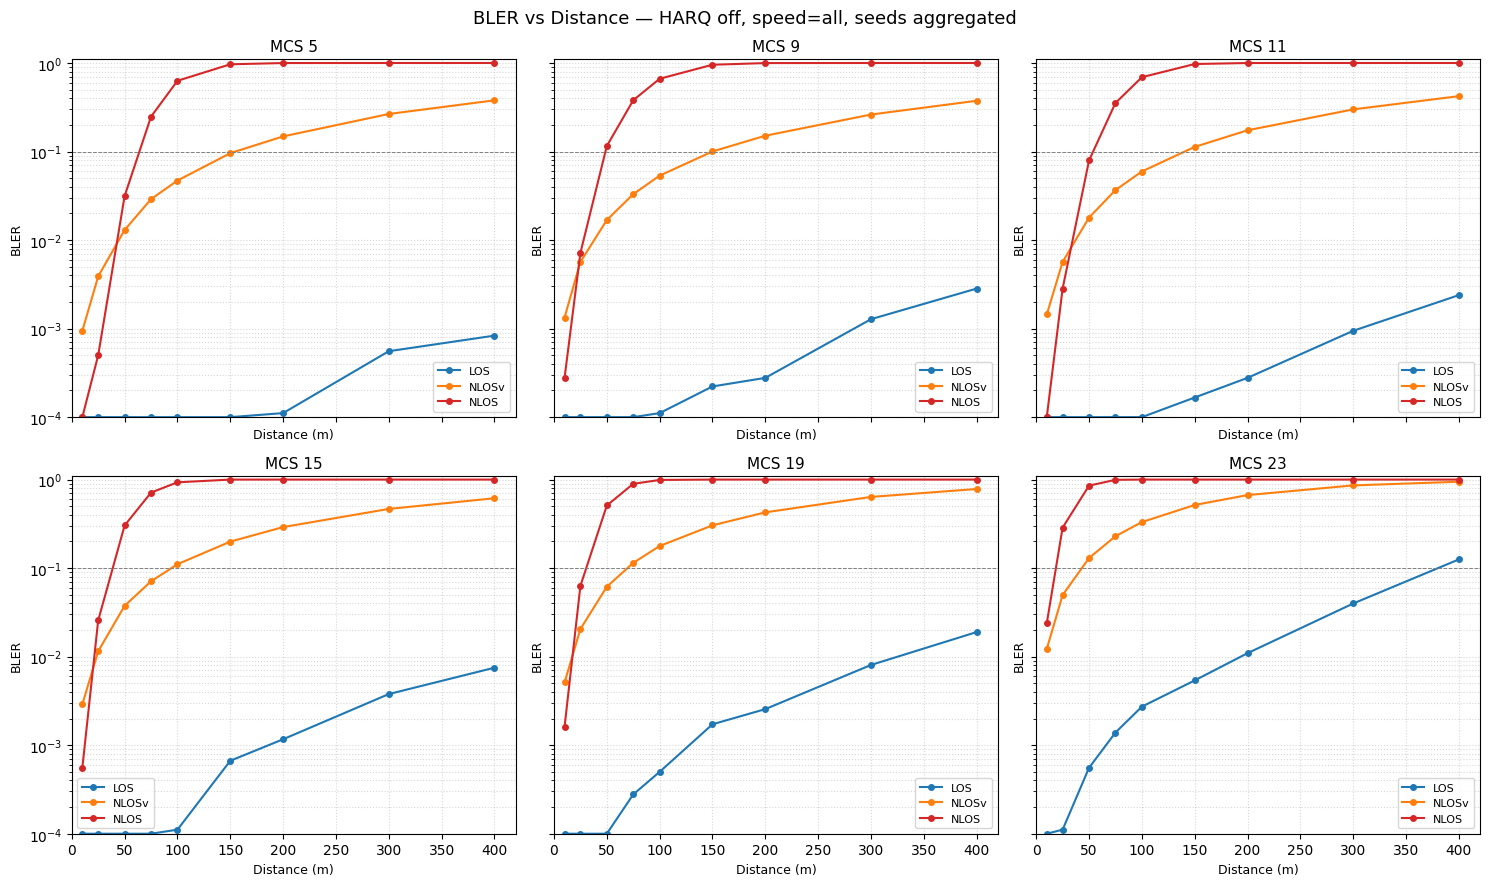

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9), sharex=True, sharey=True)
axes = axes.flatten()

sub = df[df['harq'] == 0]
for ax, mcs in zip(axes, mcs_list):
    m = sub[sub['mcs'] == mcs]
    for cond in COND_ORDER:
        c = m[m['channel_condition'] == cond]
        if c.empty:
            continue
        g = agg(c, ['distance_m'])
        ax.semilogy(g['distance_m'], g['bler'].clip(1e-4),
                    color=COND_COLOR[cond], marker='o', markersize=4,
                    label=COND_LABELS[cond])
    ax.set_title(f'MCS {mcs}', fontsize=11)
    ax.set_xlim(0, 420)
    ax.set_ylim(1e-4, 1.1)
    ax.axhline(0.1, color='grey', lw=0.7, ls='--')
    ax.grid(True, which='both', ls=':', alpha=0.5)
    ax.legend(fontsize=8)

for ax in axes:
    ax.set_xlabel('Distance (m)', fontsize=9)
    ax.set_ylabel('BLER', fontsize=9)

fig.suptitle('BLER vs Distance — HARQ off, speed=all, seeds aggregated', fontsize=13)
plt.tight_layout()
fig.savefig(OUT / 'bler_vs_distance_by_mcs.pdf', dpi=150)
plt.show()

## 2  BLER vs mean SINR — one subplot per MCS

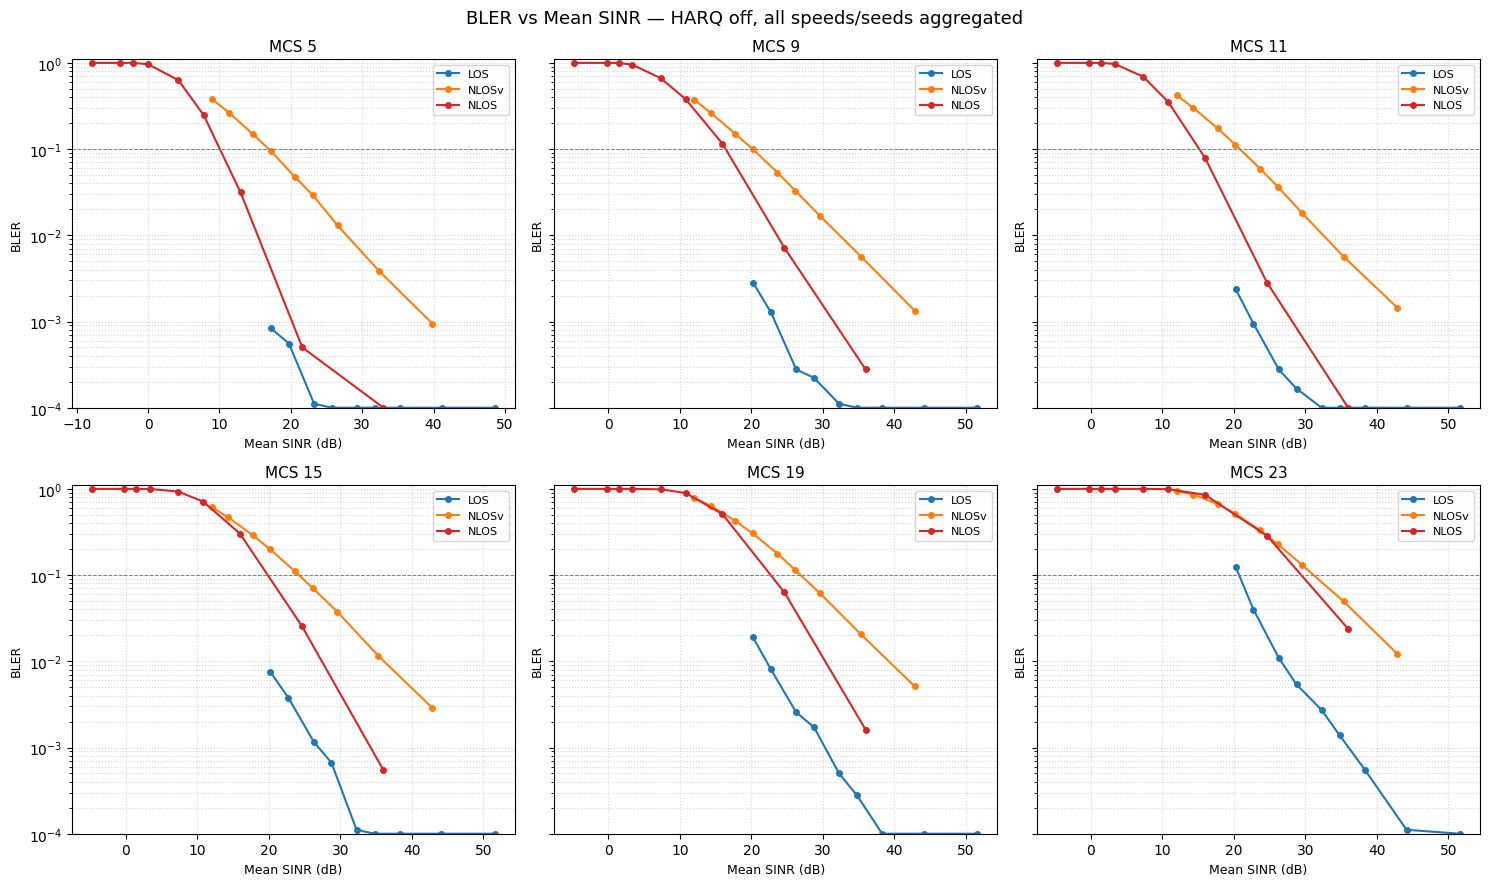

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9), sharex=False, sharey=True)
axes = axes.flatten()

sub = df[df['harq'] == 0]
for ax, mcs in zip(axes, mcs_list):
    m = sub[sub['mcs'] == mcs]
    for cond in COND_ORDER:
        c = m[m['channel_condition'] == cond]
        if c.empty:
            continue
        g = agg(c, ['distance_m'])
        g = g.dropna(subset=['mean_sinr_db'])
        g_sorted = g.sort_values('mean_sinr_db')
        ax.semilogy(g_sorted['mean_sinr_db'], g_sorted['bler'].clip(1e-4),
                    color=COND_COLOR[cond], marker='o', markersize=4,
                    label=COND_LABELS[cond])
    ax.set_title(f'MCS {mcs}', fontsize=11)
    ax.set_ylim(1e-4, 1.1)
    ax.axhline(0.1, color='grey', lw=0.7, ls='--')
    ax.grid(True, which='both', ls=':', alpha=0.5)
    ax.legend(fontsize=8)
    ax.set_xlabel('Mean SINR (dB)', fontsize=9)
    ax.set_ylabel('BLER', fontsize=9)

fig.suptitle('BLER vs Mean SINR — HARQ off, all speeds/seeds aggregated', fontsize=13)
plt.tight_layout()
fig.savefig(OUT / 'bler_vs_sinr_by_mcs.pdf', dpi=150)
plt.show()

## 2b  BLER vs mean SINR — colored by MCS, one subplot per channel condition

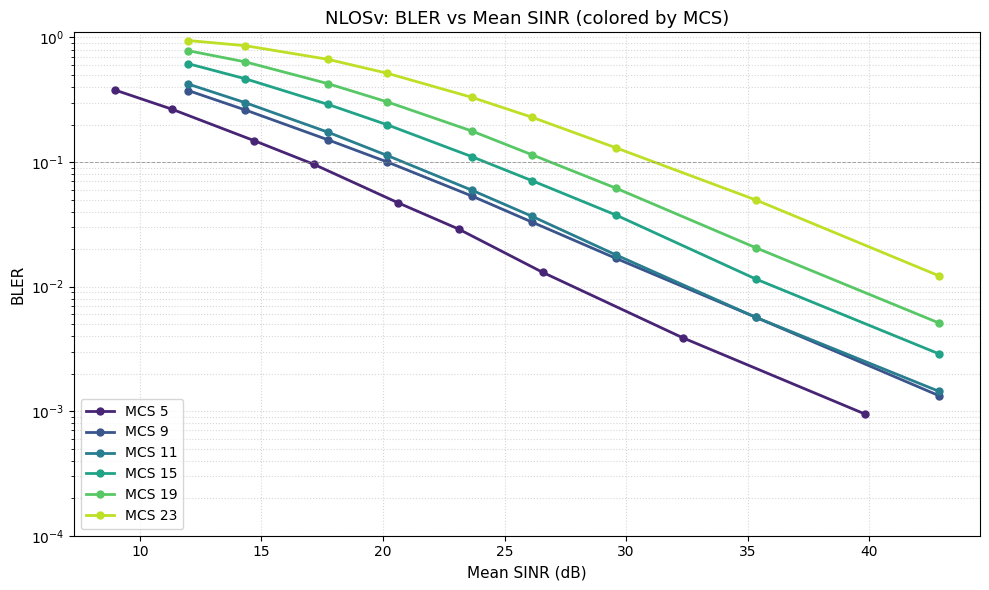

In [12]:
fig, ax = plt.subplots(figsize=(10, 6))

sub = df[(df['harq'] == 0) & (df['channel_condition'] == 'nlosv')]
for mcs in mcs_list:
    m = sub[sub['mcs'] == mcs]
    if m.empty:
        continue
    g = agg(m, ['distance_m'])
    g = g.dropna(subset=['mean_sinr_db'])
    g_sorted = g.sort_values('mean_sinr_db')
    ax.semilogy(g_sorted['mean_sinr_db'], g_sorted['bler'].clip(1e-4),
                color=mcs_color[mcs], marker='o', markersize=5,
                label=f'MCS {mcs}', linewidth=2)

ax.set_title('NLOSv: BLER vs Mean SINR (colored by MCS)', fontsize=13)
ax.set_xlabel('Mean SINR (dB)', fontsize=11)
ax.set_ylabel('BLER', fontsize=11)
ax.set_ylim(1e-4, 1.1)
ax.axhline(0.1, color='grey', lw=0.7, ls='--', alpha=0.7)
ax.grid(True, which='both', ls=':', alpha=0.5)
ax.legend(fontsize=10, loc='best')
plt.tight_layout()
fig.savefig(OUT / 'bler_vs_sinr_nlosv_by_mcs.pdf', dpi=150)
plt.show()

## 2c  BLER vs distance for NLOSv — colored by MCS

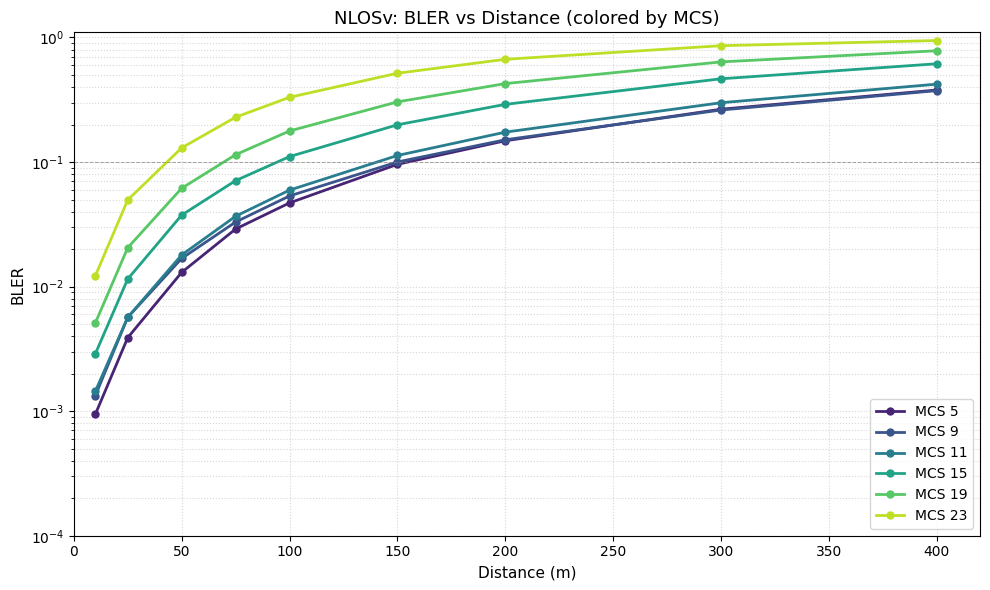

In [13]:
fig, ax = plt.subplots(figsize=(10, 6))

sub = df[(df['harq'] == 0) & (df['channel_condition'] == 'nlosv')]
for mcs in mcs_list:
    m = sub[sub['mcs'] == mcs]
    if m.empty:
        continue
    g = agg(m, ['distance_m'])
    ax.semilogy(g['distance_m'], g['bler'].clip(1e-4),
                color=mcs_color[mcs], marker='o', markersize=5,
                label=f'MCS {mcs}', linewidth=2)

ax.set_title('NLOSv: BLER vs Distance (colored by MCS)', fontsize=13)
ax.set_xlabel('Distance (m)', fontsize=11)
ax.set_ylabel('BLER', fontsize=11)
ax.set_xlim(0, 420)
ax.set_ylim(1e-4, 1.1)
ax.axhline(0.1, color='grey', lw=0.7, ls='--', alpha=0.7)
ax.grid(True, which='both', ls=':', alpha=0.5)
ax.legend(fontsize=10, loc='best')
plt.tight_layout()
fig.savefig(OUT / 'bler_vs_distance_nlosv_by_mcs.pdf', dpi=150)
plt.show()

## 2d  BLER vs speed for NLOSv — colored by MCS

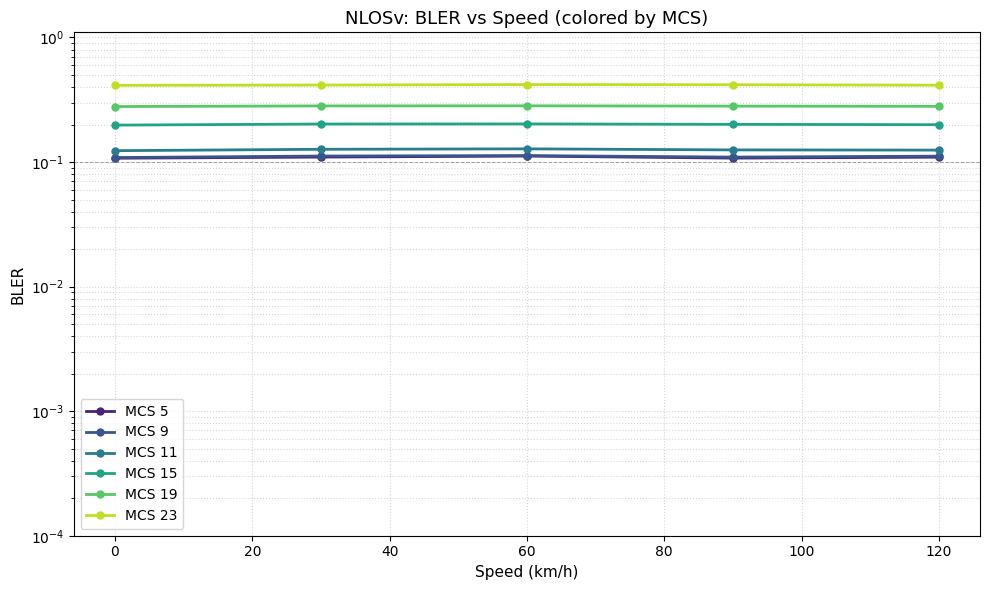

In [14]:
fig, ax = plt.subplots(figsize=(10, 6))

sub = df[(df['harq'] == 0) & (df['channel_condition'] == 'nlosv')]
for mcs in mcs_list:
    m = sub[sub['mcs'] == mcs]
    if m.empty:
        continue
    g = agg(m, ['speed_kmh'])
    g_sorted = g.sort_values('speed_kmh')
    ax.semilogy(g_sorted['speed_kmh'], g_sorted['bler'].clip(1e-4),
                color=mcs_color[mcs], marker='o', markersize=5,
                label=f'MCS {mcs}', linewidth=2)

ax.set_title('NLOSv: BLER vs Speed (colored by MCS)', fontsize=13)
ax.set_xlabel('Speed (km/h)', fontsize=11)
ax.set_ylabel('BLER', fontsize=11)
ax.set_ylim(1e-4, 1.1)
ax.axhline(0.1, color='grey', lw=0.7, ls='--', alpha=0.7)
ax.grid(True, which='both', ls=':', alpha=0.5)
ax.legend(fontsize=10, loc='best')
plt.tight_layout()
fig.savefig(OUT / 'bler_vs_speed_nlosv_by_mcs.pdf', dpi=150)
plt.show()

## 2e  BLER vs distance and speed for NLOSv (3D) — colored by MCS

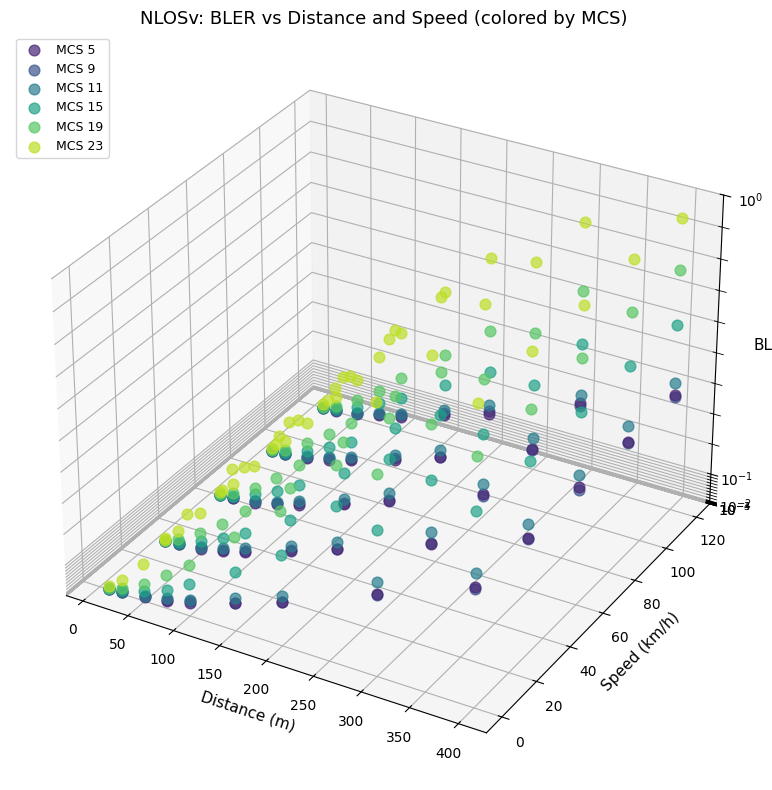

In [15]:
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

sub = df[(df['harq'] == 0) & (df['channel_condition'] == 'nlosv')]

# Aggregate by both distance and speed per MCS
for mcs in mcs_list:
    m = sub[sub['mcs'] == mcs]
    if m.empty:
        continue
    g = agg(m, ['distance_m', 'speed_kmh'])
    
    # Plot scatter points for this MCS
    ax.scatter(g['distance_m'], g['speed_kmh'], g['bler'].clip(1e-4),
              color=mcs_color[mcs], s=60, alpha=0.7,
              label=f'MCS {mcs}', depthshade=False)

ax.set_xlabel('Distance (m)', fontsize=11)
ax.set_ylabel('Speed (km/h)', fontsize=11)
ax.set_zlabel('BLER', fontsize=11)
ax.set_zlim(1e-4, 1)
ax.set_zscale('log')
ax.set_title('NLOSv: BLER vs Distance and Speed (colored by MCS)', fontsize=13)
ax.legend(fontsize=9, loc='upper left')
plt.tight_layout()
fig.savefig(OUT / 'bler_vs_distance_speed_3d_nlosv_by_mcs.pdf', dpi=150)
plt.show()

## 3  Mean SINR vs distance — by channel condition

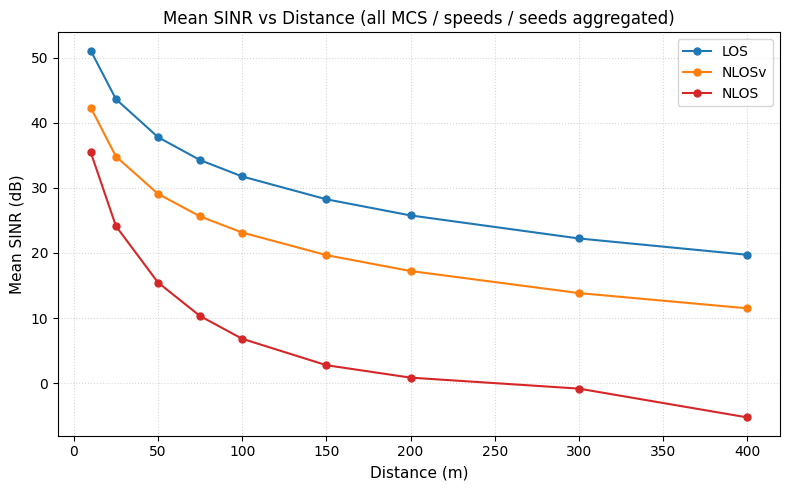

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))
sub = df[df['harq'] == 0]
for cond in COND_ORDER:
    c = sub[sub['channel_condition'] == cond]
    g = agg(c, ['distance_m'])
    ax.plot(g['distance_m'], g['mean_sinr_db'],
            color=COND_COLOR[cond], marker='o', markersize=5,
            label=COND_LABELS[cond])

ax.set_xlabel('Distance (m)', fontsize=11)
ax.set_ylabel('Mean SINR (dB)', fontsize=11)
ax.set_title('Mean SINR vs Distance (all MCS / speeds / seeds aggregated)', fontsize=12)
ax.legend(fontsize=10)
ax.grid(True, ls=':', alpha=0.5)
plt.tight_layout()
fig.savefig(OUT / 'sinr_vs_distance_by_cond.pdf', dpi=150)
plt.show()

## 4  Speed effect on BLER (MCS 11, all conditions)

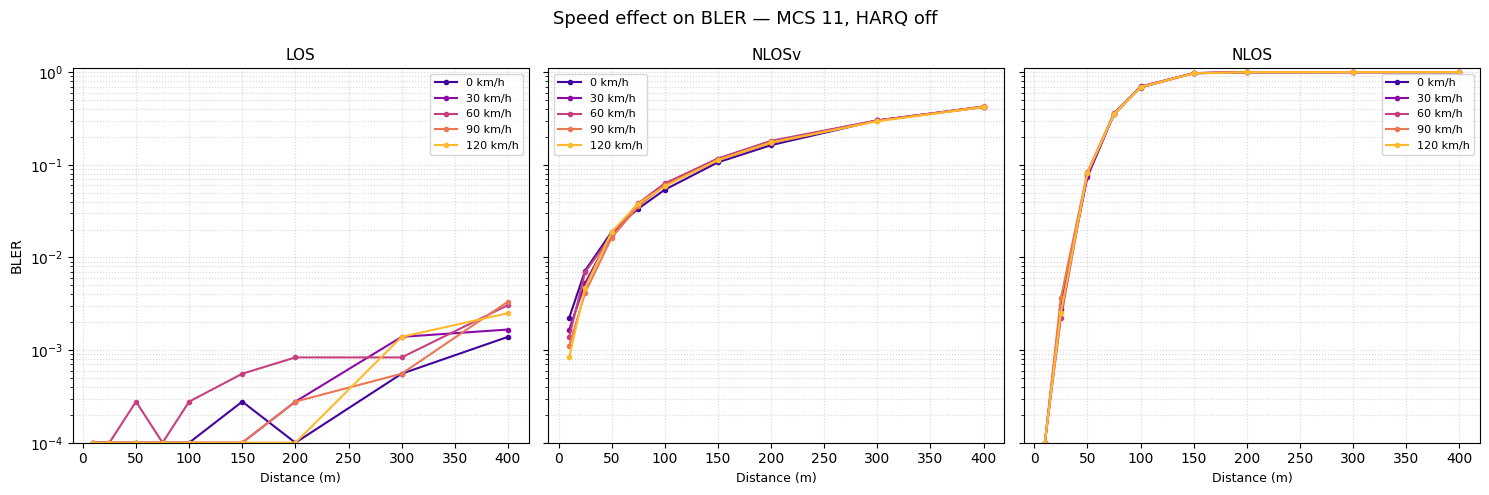

In [7]:
FOCUS_MCS = 11
speed_colors = plt.cm.plasma(np.linspace(0.1, 0.85, df['speed_kmh'].nunique()))
speed_list = sorted(df['speed_kmh'].unique())
speed_color = dict(zip(speed_list, speed_colors))

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
sub = df[(df['mcs'] == FOCUS_MCS) & (df['harq'] == 0)]
for ax, cond in zip(axes, COND_ORDER):
    c = sub[sub['channel_condition'] == cond]
    for spd in speed_list:
        s = c[c['speed_kmh'] == spd]
        if s.empty:
            continue
        g = agg(s, ['distance_m'])
        ax.semilogy(g['distance_m'], g['bler'].clip(1e-4),
                    color=speed_color[spd], marker='o', markersize=3,
                    label=f'{int(spd)} km/h')
    ax.set_title(f'{COND_LABELS[cond]}', fontsize=11)
    ax.set_xlabel('Distance (m)', fontsize=9)
    ax.set_ylim(1e-4, 1.1)
    ax.grid(True, which='both', ls=':', alpha=0.5)
    ax.legend(fontsize=8)

axes[0].set_ylabel('BLER', fontsize=10)
fig.suptitle(f'Speed effect on BLER — MCS {FOCUS_MCS}, HARQ off', fontsize=13)
plt.tight_layout()
fig.savefig(OUT / f'bler_vs_dist_speed_mcs{FOCUS_MCS}.pdf', dpi=150)
plt.show()

## 5  HARQ gain

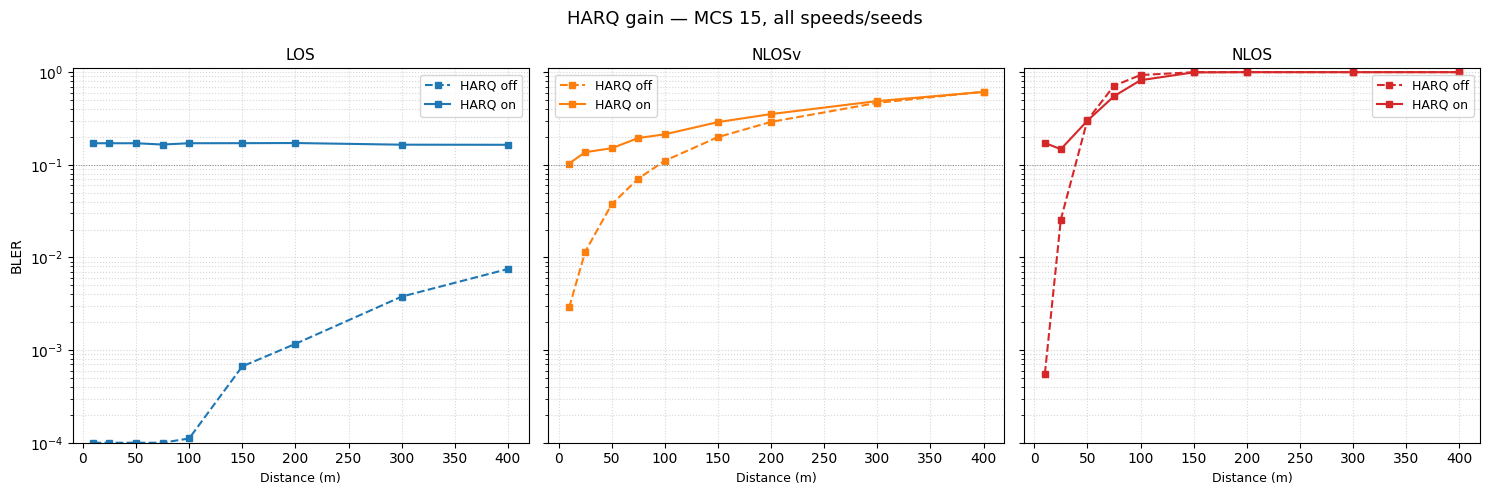

In [8]:
FOCUS_MCS2 = 15
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
sub = df[df['mcs'] == FOCUS_MCS2]
for ax, cond in zip(axes, COND_ORDER):
    c = sub[sub['channel_condition'] == cond]
    for harq_val, ls, lbl in [(0, '--', 'HARQ off'), (1, '-', 'HARQ on')]:
        h = c[c['harq'] == harq_val]
        if h.empty:
            continue
        g = agg(h, ['distance_m'])
        ax.semilogy(g['distance_m'], g['bler'].clip(1e-4),
                    ls=ls, marker='s', markersize=4,
                    color=COND_COLOR[cond], label=lbl)
    ax.set_title(f'{COND_LABELS[cond]}', fontsize=11)
    ax.set_xlabel('Distance (m)', fontsize=9)
    ax.set_ylim(1e-4, 1.1)
    ax.axhline(0.1, color='grey', lw=0.7, ls=':')
    ax.grid(True, which='both', ls=':', alpha=0.5)
    ax.legend(fontsize=9)

axes[0].set_ylabel('BLER', fontsize=10)
fig.suptitle(f'HARQ gain — MCS {FOCUS_MCS2}, all speeds/seeds', fontsize=13)
plt.tight_layout()
fig.savefig(OUT / f'harq_gain_mcs{FOCUS_MCS2}.pdf', dpi=150)
plt.show()

## 6  Summary table — 10% BLER distance per (MCS, condition, HARQ)

In [9]:
from scipy.interpolate import interp1d

rows = []
for mcs in mcs_list:
    for cond in COND_ORDER:
        for harq_val in [0, 1]:
            sub = df[(df['mcs'] == mcs) & (df['channel_condition'] == cond)
                     & (df['harq'] == harq_val)]
            if sub.empty:
                continue
            g = agg(sub, ['distance_m']).sort_values('distance_m')
            g = g.dropna(subset=['bler'])
            if len(g) < 2:
                continue
            try:
                f = interp1d(g['bler'].values, g['distance_m'].values,
                             bounds_error=False, fill_value=float('nan'))
                d10 = float(f(0.10))
            except Exception:
                d10 = float('nan')
            rows.append({'mcs': mcs, 'condition': cond,
                         'harq': 'on' if harq_val else 'off',
                         'd_10pct_bler_m': round(d10, 1)})

summary = pd.DataFrame(rows)
print(summary.pivot_table(index=['mcs', 'harq'], columns='condition',
                          values='d_10pct_bler_m').to_string())
summary.to_csv(OUT / 'bler10_range_summary.csv', index=False)
print('\nSaved ->', OUT / 'bler10_range_summary.csv')

condition    los  nlos  nlosv
mcs harq                     
5   off      NaN  57.9  153.9
    on       NaN  18.2    NaN
9   off      NaN  46.4  149.8
    on       NaN   NaN   14.6
11  off      NaN  51.9  137.9
    on       NaN   NaN   15.3
15  off      NaN  31.7   93.3
19  off      NaN  27.1   68.1
23  off    370.3  14.3   40.7

Saved -> results/figures/bler10_range_summary.csv
